# 2. Features and splits

Two jobs in this notebook, and the second one is where most molecular machine
learning quietly goes wrong.

**Features.** Turn a structure into numbers, twice. Once as physical
descriptors for the Gaussian process, once as a fingerprint for the
interpretability branch and for a chemistry-aware kernel.

**Splits.** Decide which molecules the model is allowed to learn from. Get
this wrong and every score in the rest of the project is fiction.

In [9]:
import sys, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore"); torch.set_num_threads(2)
sys.path.insert(0, "/Users/arujatiwary/Downloads/molecular-sdl/src")
from molsdl import chem, features, models, plotting

plotting.use_style()
d = pickle.load(open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/datasets.pkl", "rb"))
egfr, D_egfr = d["egfr"], d["D_egfr"]
esol, D_esol = d["esol"], d["D_esol"]
kiba, D_kiba = d["kiba"], d["D_kiba"]
print(f"EGFR {len(egfr)}, ESOL {len(esol)}, KIBA {len(kiba)}")

EGFR 5531, ESOL 1117, KIBA 2065


## Two views of the same molecule

**Descriptors** are physical quantities: molecular weight, calculated logP,
polar surface area, ring counts. They are interpretable, there are only about
200 of them, and they suit a Gaussian process with a distance-based kernel.
They are the right choice for a property driven by bulk physics, such as
solubility.

**Morgan fingerprints** record which substructures are present. Each bit says
"this molecule contains this atom environment". They are the right choice for
a property driven by specific contacts with a protein, such as potency, and
they are what makes the SHAP work in section 6 possible.

Keeping both, and using each where it belongs, is worth more than arguing
about which is better.

In [10]:
fp_egfr = (chem.morgan_counts(egfr.std_smiles.tolist()) > 0).astype(float)
fp_esol = (chem.morgan_counts(esol.std_smiles.tolist()) > 0).astype(float)
print(f"fingerprints: {fp_egfr.shape}, average {fp_egfr.sum(1).mean():.0f} bits set per molecule")
print(f"descriptors:  {D_egfr.shape}")

fingerprints: (5531, 2048), average 56 bits set per molecule
descriptors:  (5531, 204)


## Pruning the descriptors

Raw RDKit descriptors include many near-copies of each other. Feeding 200
correlated columns to a GP with one lengthscale per column means fitting 200
hyperparameters on a few hundred molecules, which goes badly.

`FeatureBuilder` drops constant columns, drops one of every pair correlated
above 0.92, clips extremes to training quantiles so a single odd molecule
cannot stretch the scale, and standardises. Every one of those decisions is
learned on the training set and applied unchanged elsewhere.

In [11]:
fb = features.FeatureBuilder(corr_max=0.92, max_features=45).fit(D_esol)
print(f"{D_esol.shape[1]} descriptors -> {fb.n_features} kept")
print("first 12 survivors:", ", ".join(fb.columns_[:12]))

204 descriptors -> 45 kept
first 12 survivors: BertzCT, MolWt, TPSA, Kappa3, SMR_VSA7, SMR_VSA5, PEOE_VSA6, SMR_VSA10, PEOE_VSA7, SlogP_VSA12, EState_VSA9, SlogP_VSA2


## The split that matters

A random split puts close analogues on both sides. Molecule 4,101 differs
from molecule 4,102 by one methyl group; if one is in training and the other
in test, the model looks brilliant and has learned nothing transferable.

A **scaffold split** groups molecules by their Bemis-Murcko scaffold, the ring
systems plus the linkers between them, and keeps whole groups on one side.
The test set is then made of chemistry the model has never seen.

This is the same principle as a deduplication key that includes the outcome
rather than only the inputs: the question is always "what is the real unit of
independence here", and it is almost never the row.

In [12]:
scaf = [chem.murcko_scaffold(s) for s in egfr.std_smiles]
counts = pd.Series(scaf).value_counts()
print(f"{len(egfr)} molecules share {len(counts)} distinct scaffolds")
print(f"largest scaffold group: {counts.iloc[0]} molecules")
print(f"scaffolds appearing once: {(counts == 1).sum()}")

5531 molecules share 1865 distinct scaffolds
largest scaffold group: 507 molecules
scaffolds appearing once: 1239


### What the two splits do to a score

Same data, same model, same features. Only the split changes.

In [13]:
y = egfr.pIC50.values
rng = np.random.default_rng(0)

tr_s, _, te_s = chem.scaffold_split(egfr.std_smiles.tolist(), 0.70, 0.12,
                                    seed=0, balanced=False)
tr_s = rng.choice(tr_s, 2000, replace=False)

perm = rng.permutation(len(y))
tr_r, te_r = perm[:2000], perm[2000:2000 + len(te_s)]

rows = []
for name, tr, te in [("random split", tr_r, te_r), ("scaffold split", tr_s, te_s)]:
    st = features.TargetScaler().fit(y[tr])
    g = models.fit_gp(fp_egfr[tr], st.transform(y[tr]),
                      n_kernel_dims=fp_egfr.shape[1], kernel="tanimoto", maxiter=100)
    mu, _ = models.gp_predict(g, fp_egfr[te])
    r = models.regression_report(y[te], st.inverse(mu)); r["split"] = name
    rows.append(r)
    print(f"{name:16s} R2 {r['R2']:6.3f}   RMSE {r['RMSE']:.2f} pIC50 units")

random split     R2  0.661   RMSE 0.81 pIC50 units
scaffold split   R2  0.630   RMSE 0.94 pIC50 units


The gap is not small, and it is not a bug. The random-split number is what
you get for interpolating inside families you have already seen. The
scaffold-split number is what you get when a chemist hands you a new series,
which is the situation that actually arises.

Every score in this project is a scaffold-split score.

  saved ../outputs/figures/02_split_comparison.png


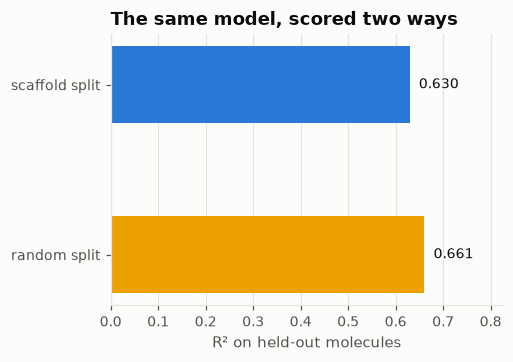

In [14]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
vals = [r["R2"] for r in rows]
names = [r["split"] for r in rows]
bars = ax.barh(names, vals, height=0.45,
               color=[plotting.C[3], plotting.C[0]])
for b, v in zip(bars, vals):
    ax.annotate(f"{v:.3f}", xy=(v, b.get_y() + b.get_height()/2),
                xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=plotting.INK)
ax.set_xlim(0, max(vals) * 1.25)
ax.set_xlabel("R² on held-out molecules")
ax.set_title("The same model, scored two ways")
ax.grid(axis="y", visible=False)
plotting.save(fig, "02_split_comparison")
plt.show()

## A chemistry-aware kernel

A Gaussian process needs to know when two molecules are similar. On raw
fingerprint bits, a squared-exponential kernel measures how many bits differ,
which is a poor stand-in for chemical similarity because it ignores how many
bits are set in the first place.

The **Tanimoto kernel** uses the similarity measure chemists already use:

$$k(x, y) = \frac{\langle x, y\rangle}{|x|^2 + |y|^2 - \langle x, y\rangle}$$

It has almost no hyperparameters, so it fits quickly and stably on the small
training sets an active learning loop starts with.

pairwise Tanimoto similarity: median 0.146, 95th percentile 0.345
  saved ../outputs/figures/02_similarity_distribution.png


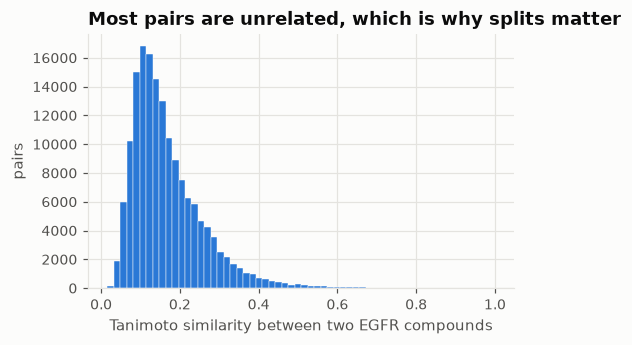

In [15]:
sub = rng.choice(len(egfr), 400, replace=False)
S = chem.tanimoto_matrix(fp_egfr[sub], fp_egfr[sub])
off = S[~np.eye(len(sub), dtype=bool)]
print(f"pairwise Tanimoto similarity: median {np.median(off):.3f}, "
      f"95th percentile {np.quantile(off, 0.95):.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(off, bins=60, color=plotting.C[0], edgecolor=plotting.SURFACE, linewidth=0.3)
ax.set_xlabel("Tanimoto similarity between two EGFR compounds")
ax.set_ylabel("pairs")
ax.set_title("Most pairs are unrelated, which is why splits matter")
plotting.save(fig, "02_similarity_distribution")
plt.show()

## Save the features

In [16]:
np.save("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/fp_egfr.npy", fp_egfr)
np.save("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/fp_esol.npy", fp_esol)
pickle.dump({"feature_builder_esol": fb},
            open("/Users/arujatiwary/Downloads/molecular-sdl/data/processed/features.pkl", "wb"))
print("saved")

saved


## What just happened

Every molecule now has two numerical descriptions, and the project has a
splitting rule that does not flatter itself. The measured cost of getting the
split wrong, on this data, is roughly 0.4 of R².

Next: the two-tier model.